# 46500 part 5: Structural Reliability
## 1. Introduction

The structural reliability problem seeks to compute the probability of a structure failing, while taking into account the uncertainties in the structure's properties (material strength, carrying capacity, etc.) and the uncertainties in the loading acting on the structure.

The reliability problem is formulated by means of a limit state function $g(\mathbf{X})$ which describes the state of the structure:

- $g(\mathbf{X}) < 0$ means failure
- $g(\mathbf{X}) = 0$ means we are precisely at the failure boundary - typically also considered as failure
- $g(\mathbf{X}) > 0$ belongs to the "safe" set of values.

In the above, the variable $X$ denotes the vector of random variables that form the input to $g(\mathbf{X})$. $\mathbf{X}$ is defined by its joint probability distribution, $f(\mathbf{X})$. 

Typically, the limit state function will be divided into a "load" (denoted by "$S$" from the word "strain") and "resistance" part (denoted by "$R$"). Hence, one can define the limit state and failure as $g(\mathbf{X}) = R(\mathbf{X}) - S(\mathbf{X}) \leq 0$.

Solving the reliability problem amounts to integrating (finding the total probability volume) over the space where $g(\mathbf{X})\leq0$. This can be described by an "indicator" function $i_g$ which is 0 if $g(\mathbf{X}) > 0$ and 1 if $g(\mathbf{X})\leq0$:

$P_f = \int{ {i_g \left[g(\mathbf{X}) \leq 0 \right]}  f_{\mathbf{X}}(\mathbf{X})\mathrm{d}\mathbf{X} }$

In the following, we will train several methods to compute this integral. 

## 2. Elementary reliability exercise

Let us consider the following Normally (Gaussian) distributed, uncorrelated random variables:

________________________________________
    Variable Name |   Mean  |   C.o.v  |
        x1        |   10    |    0.1   |
        x2        |   20    |    0.3   |
        x3        |   10    |    0.15  |
        x4        |   20    |    0.4   |
        x5        |   40    |    0.2   |
________________________________________

To begin with, we can solve a few simple limit states:

- $g_1 = 5x_1 - x_2$
- $g_2 = 8x_1 + 4x_3 + 6x_4 - 2x_5$

In this simplified case, we have sufficient information to compute the probability that each of these functions will be less than zero:
- We know that all variables are Gaussian distributed and independent
- A sum of independent Gaussian (Normally distributed) variables is also Normally distributed, with distribution parameters as follows: 
    - $E[aX+bY] = aE[X] + bE[Y]$
    - $Var[aX+bY] = a^2Var[X] + b^2Var[Y]$

Given the above, we can compute the probability that $M = g(X) = R - S <= 0$ by taking the  normal CDF at 0 for a distribution with mean and variance computed as shown above. 

Another simple alternative method for computing reliability is Monte Carlo. Reminding what you've seen in the lecture slides and videos, failure probability using Monte Carlo can be computed by:

$P_{f,MC} = \frac{1}{N}\sum{g(\mathbf{X}) \leq 0}$

where $N$ is the number of Monte Carlo samples (limit state function evaluations), and $g(\mathbf{X}) \leq 0$ is a Boolean variable equal to 1 if the condition is true, and 0 if otherwise.

### Coding exercise - elementary reliability

In the following code cells, please compute the reliability (probability of failure) for the simple limit state functions $g_1$ and $g_2$, using:
1) The analytical formula defined above
2) A Monte Carlo simulation

In [ ]:
# Compute analytically probability of failure for g1
import numpy as np
import scipy.stats as stats
Mu_g1 = 5*10 - 1*20
print("Mean of g1: " + str(Mu_g1))
Sigma_g1 = np.sqrt(5*5*(0.1*10)**2 + 1*1*(0.3*20)**2)
print("Standard devitaion of g1: " + str(Sigma_g1))

P_f = stats.norm.cdf(0,loc = Mu_g1, scale = Sigma_g1)
Beta = stats.norm.ppf(1 - P_f)

Beta_1 = Mu_g1/Sigma_g1
P_f_1 = stats.norm.cdf(-Beta_1)

print('Analytically computed failure probability: ' + str(P_f))
print('Reliability index: ' + str(Beta))
print('Reliability index - alternative computation:' + str(Beta_1))
print('Probability of failure - alternative computation:' + str(P_f_1))

Let us also plot the distributions of the variables:

In [ ]:
import matplotlib.pyplot as plt
fig0,ax0 = plt.subplots(1,2,figsize = (10,5))
x = np.arange(-10,150,1)
ax0[0].plot(x,stats.norm.pdf(x,loc = 5*10, scale = 5*0.1*10),'-r', label = "5X1")
ax0[0].plot(x,stats.norm.pdf(x,loc = 1*20, scale = 1*0.3*20),'-b', label = "X2")
ax0[0].plot(x,stats.norm.pdf(x,loc = Mu_g1, scale = Sigma_g1),'--k', linewidth = 0.5, label = 'g1 = 5X1 - X2')
ax0[0].set_xlabel('x, g')
ax0[0].set_ylabel('f(x), f(g)')
ax0[0].legend()
ax0[1].plot(x,stats.norm.pdf(x,loc = Mu_g1, scale = Sigma_g1),'-k', linewidth = 0.5, label = 'g1 = 5X1 - X2')
ax0[1].set_xlabel('g')
ax0[1].set_ylabel('f(g)')
ax0[1].legend()
ax0[1].plot([0, 0], [0, 1],'--k')
ax0[1].set_xlim([-1,3])
ax0[1].set_ylim([0,0.005])
plt.tight_layout()
plt.show()

In [ ]:
# Compute the above exercise with Monte Carlo

N_MC = 1e5

F_x1 = np.random.rand(int(N_MC))
x1 = stats.norm.ppf(F_x1, loc = 10, scale = 0.1*10)
F_x2 = np.random.rand(int(N_MC))
x2 = stats.norm.ppf(F_x2, loc = 20, scale = 0.3*20)
g_MC = 5*x1 - x2
Pf_MC = np.sum(g_MC <= 0)/N_MC
Beta_MC = stats.norm.ppf(1 - Pf_MC)

print('Number of failure events observed: ' + str(np.sum(g_MC <= 0)))
print('Failure probability from Monte Carlo: ' + str(Pf_MC))
print('Reliability index from Monte Carlo: ' + str(Beta_MC))

In [ ]:
fig3,ax3 = plt.subplots(2,2,figsize = (10,10))
ax3[0,0].hist(F_x1,50)
ax3[0,0].set_xlabel('F_x1')
ax3[0,0].set_ylabel('Counts')
ax3[0,0].set_title('Histogram of F_x1')
ax3[0,1].hist(x1,50)
ax3[0,1].set_xlabel('x1')
ax3[0,1].set_ylabel('Counts')
ax3[0,1].set_title('Histogram of x1')
ax3[1,0].hist(F_x2,50)
ax3[1,0].set_xlabel('F_x2')
ax3[1,0].set_ylabel('Counts')
ax3[1,0].set_title('Histogram of F_x2')
ax3[1,1].hist(x2,50)
ax3[1,1].set_xlabel('x2')
ax3[1,1].set_ylabel('Counts')
ax3[1,1].set_title('Histogram of x2')

Let us now repeat the same computations for g2:

In [ ]:
# ENTER YOUR CODE HERE

N_MC = int(1e6)
F_x1 = np.random.rand(N_MC)
F_x3 = np.random.rand(N_MC)
F_x4 = np.random.rand(N_MC)
F_x5 = np.random.rand(N_MC)
x1 = stats.norm.ppf(F_x1, loc = 10, scale = 0.1*10)
x3 = stats.norm.ppf(F_x3, loc = 10, scale = 0.15*10)
x4 = stats.norm.ppf(F_x4, loc = 20, scale = 0.4*20)
x5 = stats.norm.ppf(F_x5, loc = 40, scale = 0.2*40)

g2_MC = 8*x1 + 4*x3 + 6*x4 - 2*x5

Pf_MC2 = np.sum(g2_MC <= 0)/N_MC

print('Number of failure events observed: ' + str(np.sum(g2_MC <= 0)))
print("Probability of failure for g_2: " + str(Pf_MC2))

Mu_g2 = 8*10 + 4*10 + 6*20 - 2*40
print("Mean of g2: " + str(Mu_g2))
Sigma_g2 = np.sqrt(8*8*(0.1*10)**2 + 4*4*(0.15*10)**2 + 6*6*(0.4*20)**2 + 2*2*(0.2*40)**2)
print("Standard deviation of g2: " + str(Sigma_g2))

Pf_g2 = stats.norm.cdf(0, loc = Mu_g2, scale = Sigma_g2)
print('Probability of failure for g2 - analytical computation: ' + str(Pf_g2))

## 3. Reliability exercise - more advanced methods and limit states

In the above exercises, we tried the absolutely simplest case of reliability computation. In real-world computations, several simplifying assumptions no longer hold:
- The limit state function may be nonlinear
- Variable distributions are not necessarily Gaussian, and there may be correlations between variables

There are more advanced reliability methods which can be used to address the challenges discussed above. Some of the most common structural reliability computation methods are the Monte Carlo method (already briefly discussed above), and the FORM (First-Order Reliability Method) which is described in more details in the lecture slides. 

The FORM method makes a key simplification by assuming that the limit state can be approximated by a straigt line (in 1D) - or a hyperplane in higher dimensions. This makes it possible to estimate the probability of failure analytically, by using the slopes of the hyperplane approximating the failure surface. A few specifics of the FORM method include:
- It requires that all variables are transformed to *standard normal space* of *independent and identically distributed* (i.i.d) variables - so that all variables can be considered in the same way and the probability calculation formulas are valid. The same or similar *isoprobabilistic transformation* is required for most reliability methods apart from the Crude Monte Carlo.
- Applying the FORM method requires that the gradients of the limit state function are computed. This means we can only use the FORM method on a differentiable limit state function, and that the FORM method can become computationally inefficient (suffering the "curse of dimensionality") if the number of variables is high and if the gradients need to be computed through a finite difference scheme.

### Coding example - isoprobabilistic transformation

In the below, we'll see how a pair of two uncorrelated variables where the one is non-Gaussian are transformed to a pair of "standard Normal" variables.

The variables have the distributions:

X1: Weibull with A = 10 and k = 1.2

X2: Gaussian with mean = 5 and standard deviation of 3

In [ ]:
# Example of isoprobabilistic transformation

#generate sample from both variables
Nsamples = 10000
X1 = stats.weibull_min.ppf(np.random.rand(Nsamples), scale = 10, loc = 0, c = 1.2)
X2 = stats.norm.ppf(np.random.rand(Nsamples), loc = 5, scale = 3)

# Step 1: compute the cdf of the variables
F_X1 = stats.weibull_min.cdf(X1, scale = 10, loc = 0, c = 1.2)
F_X2 = stats.norm.cdf(X2, loc = 5, scale = 3)

# Step 2: convert to standard normal by taking an inverse Standard Normal CDF
Z1 = stats.norm.ppf(F_X1, loc = 0, scale = 1)
Z2 = stats.norm.ppf(F_X2, loc = 0, scale = 1)

# Inverse transformation - showing that the transformation is fully reversible:
X1_1 = stats.weibull_min.ppf(stats.norm.cdf(Z1), scale = 10, loc = 0, c = 1.2)
X2_1 = stats.norm.ppf(stats.norm.cdf(Z2), loc = 5, scale = 3)

# Check if inverse transformation is exact:

print(np.mean(np.abs(X1_1 - X1)))


In [ ]:
# PLOT RESULTS FROM ISOPROBABILISTIC TRANSFORMATION

fig2,ax2 = plt.subplots(2,2, figsize = (10,10))

ax2[0,0].plot(X1,X2,'ok')
ax2[0,0].set_xlabel('X1')
ax2[0,0].set_ylabel('X2')
ax2[0,0].set_title('X-space')
ax2[0,1].plot(Z1,Z2,'ob')
ax2[0,1].set_xlabel('Z1')
ax2[0,1].set_ylabel('Z2')
ax2[0,1].set_title('Z-space (normalized)')
ax2[1,0].hist(X1,50)
ax2[1,0].set_xlabel('X1')
ax2[1,0].set_ylabel('Counts')
ax2[1,0].set_title('Histogram of X1')
ax2[1,1].hist(Z1,50)
ax2[1,1].set_xlabel('z1')
ax2[1,1].set_ylabel('Counts')
ax2[1,1].set_title('Histogram of Z1')

plt.show()




### Coding task

We are given the simple limit state function

$ g(u) = -\frac{4}{25} \left(u_1 - 1 \right)^2 - u_2 + 3.5$

where $u_1$ and $u_2$ are independent, standard Normal random variables.

Your task is to determine the probability of failure and the reliability index associated with the limit state $g(u)$, using 

    a) a crude Monte Carlo simulation
    b) the First-Order Reliability Method (FORM)

Can we also use quasi-random sequences for the MC simulation and what would the result be? Are there any other ways to speed up the convergence of our simulation-based approach?

For solving the exercise using the FORM method, the gradient of $g(u)$ will be needed. Given the simple form of the limit state function, we can determine the gradient analytically as

$ \nabla_g(u) = \left [ \begin{array}{cc} -8(u_1-1)/25 \\ -1 \end{array}\right] $


In [24]:
import numpy as np
import scipy.stats as stats
import scipy.optimize

In [25]:
# Limit state function and gradient function implemented
g = lambda u: -(4/25)*(u[0] - 1)**2 - u[1] + 3.5
gradg = lambda u: np.array([(-8/25)*(u[0]-1), -1])

In [26]:
# HELPER SCRIPT: FIND THE FAILURE SURFACE FOR BETTER VISUALISATION

u1range = np.arange(-5,2.001,step = 0.1) # Range of u1 (start, stop, step)
u2range = np.zeros(u1range.shape) # Range of u2
for i in range(0,len(u1range)): # Loop over values of u1
    gfunci = lambda X2: g([u1range[i], X2])
    u2range[i] = scipy.optimize.fsolve(gfunci,0); # For each value of u1, find the corresponding u2 value which results in g(u) = 0

C:\Users\nkdi\AppData\Local\Temp\ipykernel_29328\214887458.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u2range[i] = scipy.optimize.fsolve(gfunci,0); # For each value of u1, find the corresponding u2 value which results in g(u) = 0


### Monte Carlo implementation

In [58]:
# MONTE CARLO SIMULATION
N = 100000 # Number of MC samples

u_MC = np.random.randn(N,2).T # Generate a random sample of inputs
gMC = g(u_MC) # Evaluate limit state function

Nfail = np.sum(gMC <= 0) # Count failure events
pf_MC = (1/N)*Nfail # Compute failure probability
beta_MC = -stats.norm.ppf(pf_MC)# Compute reliability index
print('Probability of failure - MC simulation: ' + str(pf_MC))
print('Reliability index - MC simulation: ' + str(beta_MC))
print('Number of failure events observed: ' + str(sum(gMC <= 0)))

Probability of failure - MC simulation: 0.00253
Reliability index - MC simulation: 2.8031890459210156
Number of failure events observed: 253


In [ ]:
gMC.shape

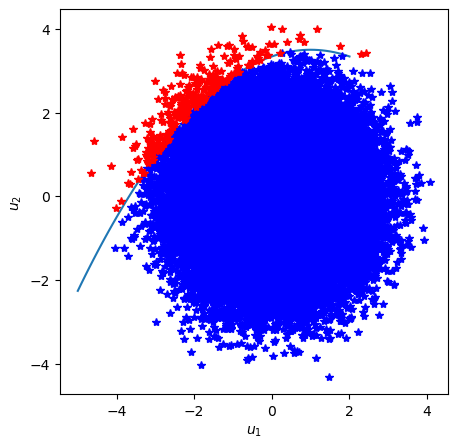

In [59]:
# Plot failure surface based on MC results
import matplotlib.pyplot as plt
fig0,axs0 = plt.subplots(figsize = (5,5))
axs0.plot(u1range,u2range)
axs0.plot(u_MC[0,gMC > 0],u_MC[1,gMC >0],'*b')
axs0.plot(u_MC[0,gMC <= 0],u_MC[1,gMC <=0],'*r')
axs0.set_xlabel('$u_1$')
axs0.set_ylabel('$u_2$')
plt.show()

In [45]:
# Try Monte Carlo with other sampling techniques (Quasi-MC)

import openturns as ot

N_samples = 100000

ot.RandomGenerator.SetSeed(0)
dim = 2

uniform_distribution = ot.ComposedDistribution([ot.Uniform(0., 1.)] * dim)

# Quasi- Monte Carlo (QMC)
QMCexperiment = ot.LowDiscrepancyExperiment(ot.SobolSequence(), uniform_distribution, N_samples, False)
SQMC = QMCexperiment.generate()
SQMC = np.asarray(SQMC).T
SQMC = stats.norm.ppf(SQMC)

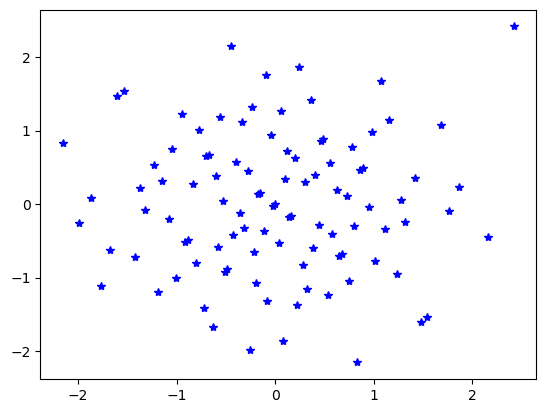

In [52]:
plt.plot(SQMC[0,:100],SQMC[1,:100],'*b')

Probability of failure: 0.00265


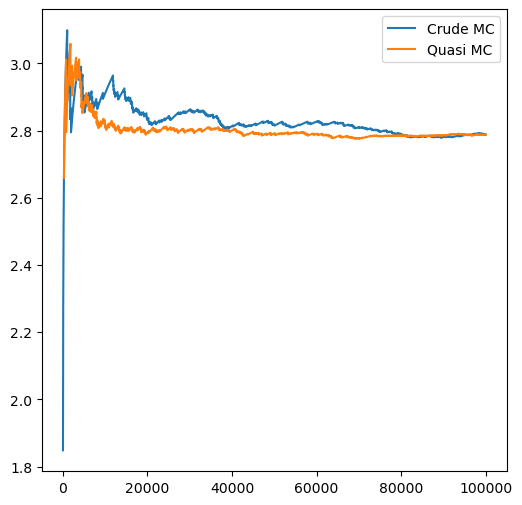

In [46]:
gQMC = g(SQMC)


print("Probability of failure: " + str(sum(gQMC<=0)/N))

betaMChist = stats.norm.ppf(1 - np.cumsum(gMC<=0)/np.arange(1,len(gMC)+1))
betaQMChist = stats.norm.ppf(1 - np.cumsum(gQMC<=0)/np.arange(1,len(gQMC)+1))


fig1,axs1 = plt.subplots(1,1,figsize = (6,6))
axs1.plot(betaMChist[:100000], label = 'Crude MC')
axs1.plot(betaQMChist[:100000], label = 'Quasi MC')
axs1.legend()
plt.show()


### FORM method implementation

With the above steps, we have completed a Crude Monte Carlo computation. The next task is to carry out the same reliability computation with the FORM method. For this reason, we'll need to set up the gradient computation as discussed.

In [55]:
# Check the gradients - analytical function vs. numerical gradients with finite difference.

u0 = np.array([0,0])
g0 = g(u0)
gradg0 = gradg(u0)
gradg01 = scipy.optimize.approx_fprime(u0,g,0.01)
gradg02 = scipy.optimize.approx_fprime(u0,g,0.0001)
print('Analytical gradient: ' + str(gradg0))
print('Finite difference gradient - large step: ' + str(gradg01))
print('Finite difference gradient - small step: ' + str(gradg02))



Analytical gradient: [ 0.32 -1.  ]
Finite difference gradient - large step: [ 0.3184 -1.    ]
Finite difference gradient - small step: [ 0.319984 -1.      ]


In [56]:
u0 = np.array([0,0])
g0 = g(u0)
gradg0 = gradg(u0)
lambda0 = ((np.dot(np.atleast_2d(gradg0), np.atleast_2d(u0).T) - g0)/(np.dot( np.atleast_2d(gradg0),np.atleast_2d(gradg0).T ))).ravel()
print(g0)
print(lambda0)
print(u0.T.shape)

3.34
[-3.02975327]
(2,)


The analysis stopped after 9 iterations.
Probability of failure - FORM: 0.0020452464511959436
Reliability index - FORM: 2.871097536316615


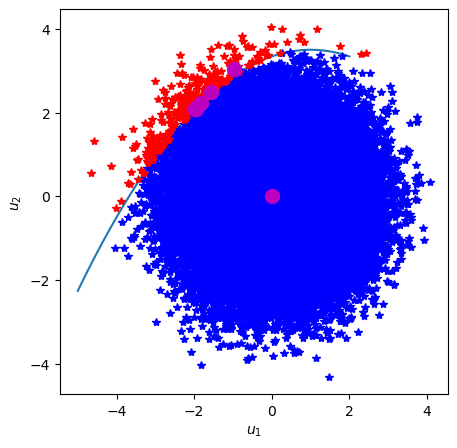

In [60]:
# FORM solution - with analytical gradients as well as with finite-difference gradients

u0 = np.array([0,0])
go = 1
itercount = 0
maxiter = 50
tol = 1e-6

ui = u0 # for the first iteration
betai = np.linalg.norm(u0)

# Plot failure surface based on MC results
import matplotlib.pyplot as plt
fig0,axs0 = plt.subplots(figsize = (5,5))
axs0.plot(u1range,u2range)
axs0.plot(u_MC[0,gMC > 0],u_MC[1,gMC >0],'*b')
axs0.plot(u_MC[0,gMC <= 0],u_MC[1,gMC <=0],'*r')
axs0.set_xlabel('$u_1$')
axs0.set_ylabel('$u_2$')


while go == 1:
    itercount+= 1
    axs0.plot(ui[0],ui[1],'om', markersize = 10)    
    gi = g(ui)
    gradgi = gradg(ui)
    
    lambdai = ((np.dot(np.atleast_2d(gradgi), np.atleast_2d(ui).T) - gi)/(np.dot( np.atleast_2d(gradgi),np.atleast_2d(gradgi).T ))).ravel()

    ui_n = lambdai*gradgi
    betai_n = np.sqrt(np.dot(ui_n,ui_n.T))
    
    epsilon = np.abs(betai_n - betai)
    if epsilon <= tol:
        go = 0
    elif itercount >= maxiter:
        go = 0
    else:
        #print(betai_n)
        ui = ui_n # update values to use in next iteration
        betai = betai_n
        
beta_FORM = betai_n
pf_FORM = stats.norm.cdf(-beta_FORM)
u_star = ui_n
        
print('The analysis stopped after ' + str(itercount) + ' iterations.')
print('Probability of failure - FORM: ' + str(pf_FORM))
print('Reliability index - FORM: ' + str(beta_FORM))        
        
    # i+= 1
    # Compute g[u_i]
    # Compute gradg[u_i]
    # Compute step size lambda
    # Compute updated value of u, u_i1
    # Compute beta_i1
    # Check tolerance and iteration number
    # u_i = u_i1, beta_i = beta_i1
   
plt.show()

In [61]:
u_star

array([-1.98187105,  2.07735125])

### Importance sampling calculation

The last method we'll try as part of this exercise is Importance Sampling. This method aims at reducing the number of simulations needed for a Monte Carlo simulation to converge, by focusing the sampling on a region of interest. In our case, a suitable region of interest may be the design point from the FORM analysis, as we expect that approximately 50% of the sample points taken at the vicinity of the design point may be within the failure domain.

In [62]:
# IMPORTANCE SAMPLING
N_IS = 1000 # Number of random samples
#u1_IS = stats.norm.ppf(np.random.rand(N_IS), loc = u_star[0], scale = 1) # Alternative
u1_IS = np.random.randn(N_IS) + u_star[0] # Random sample for u1, shifted to u* from the FORM analysis
u2_IS = np.random.randn(N_IS) + u_star[1]  # Random sample for u2, shifted to u* from the FORM analysis
u_IS = np.array([u1_IS,u2_IS])
gIS = g(u_IS)  # Evaluate g(u) in a vectorized form
                    
his = stats.norm.pdf(u1_IS - u_star[0])*stats.norm.pdf(u2_IS - u_star[1])
fis = stats.norm.pdf(u1_IS)*stats.norm.pdf(u2_IS)
ISweights = (gIS<=0)*fis/his

# Calculate the rel.index from Importance Sampling
pf_IS = np.sum(ISweights)/N_IS
beta_IS = stats.norm.ppf(1 - pf_IS)

print('Probability of failure - Importance Sampling: ' + str(pf_IS))
print('Reliability index - Importance Sampling: ' + str(beta_IS))
print('Fraction of failure events: ' + str( np.sum(gIS < 0)/N_IS))
print('Total number of failure events: ' + str(np.sum(gIS <=0)))

Probability of failure - Importance Sampling: 0.002779159646426189
Reliability index - Importance Sampling: 2.772759440226778
Fraction of failure events: 0.524
Total number of failure events: 524


In [ ]:
plt.hist(np.log10(ISweights[ISweights>0]),30)

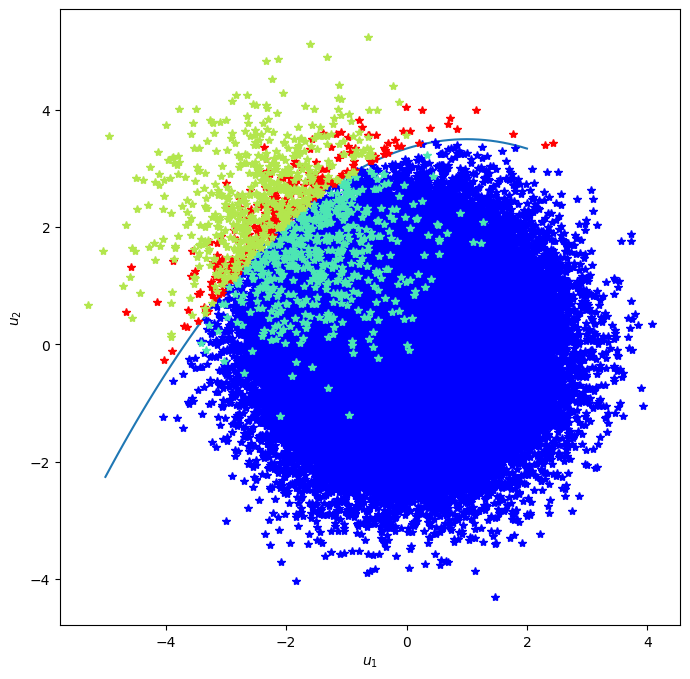

In [63]:
#% plot the Importance Sampling results along with failure surface and Monte Carlo       
fig1,axs1 = plt.subplots(figsize = (8,8))
axs1.plot(u1range,u2range)
axs1.plot(u_MC[0,gMC > 0],u_MC[1,gMC >0],'*b')
axs1.plot(u_MC[0,gMC <= 0],u_MC[1,gMC <=0],'*r')
axs1.set_xlabel('$u_1$')
axs1.set_ylabel('$u_2$')
axs1.plot(u1_IS[gIS > 0],u2_IS[gIS > 0],'*',color = (0.3,0.9,0.7))
axs1.plot(u1_IS[gIS <= 0],u2_IS[gIS <= 0],'*',color = (0.7,0.9,0.3))
plt.show()

In [ ]:
# Plot failure surface based on MC results - in case of very large MC
import matplotlib.pyplot as plt
fig2,axs2 = plt.subplots(figsize = (5,5))
z1_part = u1_MC[:10000]
z2_part = u2_MC[:10000]
g_part = gMC[:10000]
axs2.plot(u1range,u2range)
axs2.plot(z1_part[g_part > 0],z2_part[g_part >0],'*b')
axs2.plot(z1_part[g_part <= 0],z2_part[g_part <=0],'*r')
axs2.plot(u1_IS[gIS > 0],u2_IS[gIS>0],'o',color = [0.2, 0.7, 0.1],markersize  = 4)
axs2.plot(u1_IS[gIS <= 0],u2_IS[gIS<=0],'o',color = [0.7, 0.2, 0.1],markersize  = 4)
axs2.set_xlabel('$u_1$')
axs2.set_ylabel('$u_2$')
plt.show()

In [ ]:
# MONTE CARLO SIMULATION
N = 1000000 # Number of MC samples

u1 = np.random.rand(N)
u2 = np.random.rand(N)

z1 = stats.norm.ppf(u1)
z2 = stats.norm.ppf(u2)

uMC = [z1,z2]
gMC = g(uMC)

pf_MC = sum(gMC<=0)/N
beta_MC = stats.norm.ppf(1 - pf_MC)
print('Number of failure events observed: ' + str(sum(gMC<=0)))
print('Probability of failure - MC simulation: ' + str(pf_MC))
print('Reliability index - MC simulation: ' + str(beta_MC))